**Build Your First StateGraph - LangGraph Fundamentals Demo**

This notebook demonstrates building a controlled workflow using LangGraph

**SETUP & INSTALLATION**


In [9]:
import operator
from typing import Annotated, TypedDict

from IPython.display import Image, display
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.graph import END, StateGraph


**PART 1: DEFINE THE STATE**

State is the data structure that flows through our graph.

It represents what information is passed between nodes


In [2]:
class AgentState(TypedDict):
    """
    The state schema for our workflow.
    This defines what data our graph will work with.
    """

    messages: Annotated[list, operator.add]  # List of messages that accumulates
    user_input: str  # Original user input
    processing_step: str  # Track which step we're on
    result: str  # Final result


print("✓ State schema defined")
print("  - messages: accumulates conversation history")
print("  - user_input: stores the original query")
print("  - processing_step: tracks workflow progress")
print("  - result: stores the final output\n")

✓ State schema defined
  - messages: accumulates conversation history
  - user_input: stores the original query
  - processing_step: tracks workflow progress
  - result: stores the final output



**PART 2: DEFINE NODE FUNCTIONS**

Each node is a function that processes the state and returns updates


In [3]:
def input_node(state: AgentState) -> AgentState:
    """
    Node 1: Process the input and prepare for analysis
    """
    print(f" INPUT NODE: Received '{state['user_input']}'")

    return {
        "messages": [HumanMessage(content=state["user_input"])],
        "processing_step": "input_received",
    }


def analyze_node(state: AgentState) -> AgentState:
    """
    Node 2: Analyze the input (simplified for demo)
    """
    print(" ANALYZE NODE: Analyzing input...")

    user_text = state["user_input"].lower()

    # Simple analysis logic
    if "weather" in user_text:
        analysis = "Weather-related query detected"
    elif "hello" in user_text or "hi" in user_text:
        analysis = "Greeting detected"
    else:
        analysis = "General query detected"

    return {
        "messages": [AIMessage(content=f"Analysis: {analysis}")],
        "processing_step": "analyzed",
    }


def process_node(state: AgentState) -> AgentState:
    """
    Node 3: Process based on the analysis
    """
    print(" PROCESS NODE: Processing...")

    user_text = state["user_input"].lower()

    # Generate a response based on the input
    if "weather" in user_text:
        response = "I would check the weather API for current conditions."
    elif "hello" in user_text or "hi" in user_text:
        response = "Hello! How can I help you today?"
    else:
        response = f"I received your message: '{state['user_input']}'"

    return {
        "messages": [AIMessage(content=response)],
        "processing_step": "processed",
        "result": response,
    }


def output_node(state: AgentState) -> AgentState:
    """
    Node 4: Prepare final output
    """
    print(" OUTPUT NODE: Finalizing response...")

    final_message = f"Final Response: {state['result']}"

    return {
        "messages": [AIMessage(content=final_message)],
        "processing_step": "completed",
    }


print("✓ Node functions defined:")
print("  - input_node: Receives and processes user input")
print("  - analyze_node: Analyzes the input")
print("  - process_node: Generates appropriate response")
print("  - output_node: Finalizes the output\n")

✓ Node functions defined:
  - input_node: Receives and processes user input
  - analyze_node: Analyzes the input
  - process_node: Generates appropriate response
  - output_node: Finalizes the output



**PART 3: BUILD THE GRAPH**

Now we construct the StateGraph by adding nodes and edges

In [4]:
# Initialize the StateGraph with our state schema
workflow = StateGraph(AgentState)

# Add nodes to the graph
workflow.add_node("input", input_node)
workflow.add_node("analyze", analyze_node)
workflow.add_node("process", process_node)
workflow.add_node("output", output_node)

print("✓ Nodes added to graph\n")

✓ Nodes added to graph



**PART 4: DEFINE THE WORKFLOW (EDGES)**

Edges define how data flows between nodes

In [5]:
# Set the entry point (where the workflow starts)
workflow.set_entry_point("input")

# Add edges to define the flow
workflow.add_edge("input", "analyze")  # input → analyze
workflow.add_edge("analyze", "process")  # analyze → process
workflow.add_edge("process", "output")  # process → output
workflow.add_edge("output", END)  # output → END

print("✓ Workflow edges defined:")
print("  START → input → analyze → process → output → END\n")

✓ Workflow edges defined:
  START → input → analyze → process → output → END



**PART 5: COMPILE THE GRAPH**

Compile the graph to make it executable

In [6]:
app = workflow.compile()

print("✓ Graph compiled and ready to use!\n")
print("=" * 70)

✓ Graph compiled and ready to use!



**PART 6: RUN THE WORKFLOW**

Now let's test our StateGraph with different inputs

In [7]:
def run_workflow(user_input: str):
    """
    Helper function to run the workflow with given input
    """
    print(f"\n{'=' * 70}")
    print("RUNNING WORKFLOW")
    print(f"{'=' * 70}")

    # Initial state
    initial_state = {
        "messages": [],
        "user_input": user_input,
        "processing_step": "initialized",
        "result": "",
    }

    # Run the workflow
    final_state = app.invoke(initial_state)

    print(f"\n{'=' * 70}")
    print("WORKFLOW COMPLETED")
    print(f"{'=' * 70}")
    print("\n📊 Final State:")
    print(f"  - Processing Step: {final_state['processing_step']}")
    print(f"  - Result: {final_state['result']}")
    print(f"  - Total Messages: {len(final_state['messages'])}")

    return final_state

**TEST CASES**

In [8]:
print("\n" + "=" * 70)
print("DEMO: Testing the StateGraph with different inputs")
print("=" * 70)

# Test 1: Greeting
print("\n Test 1: Greeting")
run_workflow("Hello!")

# Test 2: Weather query
print("\n Test 2: Weather Query")
run_workflow("What's the weather like?")

# Test 3: General query
print("\n Test 3: General Query")
run_workflow("Tell me about LangGraph")


DEMO: Testing the StateGraph with different inputs

 Test 1: Greeting

RUNNING WORKFLOW
 INPUT NODE: Received 'Hello!'
 ANALYZE NODE: Analyzing input...
 PROCESS NODE: Processing...
 OUTPUT NODE: Finalizing response...

WORKFLOW COMPLETED

📊 Final State:
  - Processing Step: completed
  - Result: Hello! How can I help you today?
  - Total Messages: 4

 Test 2: Weather Query

RUNNING WORKFLOW
 INPUT NODE: Received 'What's the weather like?'
 ANALYZE NODE: Analyzing input...
 PROCESS NODE: Processing...
 OUTPUT NODE: Finalizing response...

WORKFLOW COMPLETED

📊 Final State:
  - Processing Step: completed
  - Result: I would check the weather API for current conditions.
  - Total Messages: 4

 Test 3: General Query

RUNNING WORKFLOW
 INPUT NODE: Received 'Tell me about LangGraph'
 ANALYZE NODE: Analyzing input...
 PROCESS NODE: Processing...
 OUTPUT NODE: Finalizing response...

WORKFLOW COMPLETED

📊 Final State:
  - Processing Step: completed
  - Result: I received your message: 'Tell 

{'messages': [HumanMessage(content='Tell me about LangGraph', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Analysis: General query detected', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content="I received your message: 'Tell me about LangGraph'", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content="Final Response: I received your message: 'Tell me about LangGraph'", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'user_input': 'Tell me about LangGraph',
 'processing_step': 'completed',
 'result': "I received your message: 'Tell me about LangGraph'"}

** VISUALIZE THE GRAPH**


GRAPH STRUCTURE


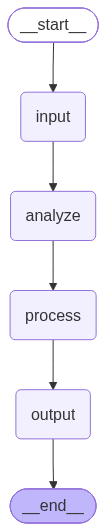

In [10]:
print("\n" + "=" * 70)
print("GRAPH STRUCTURE")
print("=" * 70)

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print("\n Graph Visualization (Text Format):")
    print("""
    ┌─────────┐
    │  START  │
    └────┬────┘
         │
         ▼
    ┌─────────┐
    │  INPUT  │  ← Entry point: Process user input
    └────┬────┘
         │
         ▼
    ┌─────────┐
    │ ANALYZE │  ← Analyze the input
    └────┬────┘
         │
         ▼
    ┌─────────┐
    │ PROCESS │  ← Generate response
    └────┬────┘
         │
         ▼
    ┌─────────┐
    │ OUTPUT  │  ← Finalize output
    └────┬────┘
         │
         ▼
    ┌─────────┐
    │   END   │
    └─────────┘
    """)

** KEY TAKEAWAYS**

In [11]:
print("\n" + "=" * 70)
print("KEY CONCEPTS DEMONSTRATED")
print("=" * 70)
print("""
✓ State Definition: Created a TypedDict to define our workflow state
✓ Node Functions: Built functions that process and update state
✓ Graph Construction: Added nodes and edges to build the workflow
✓ Linear Flow: Demonstrated a simple sequential workflow
✓ State Updates: Showed how state flows through nodes
✓ Execution: Ran the compiled graph with different inputs

NEXT STEPS:
- Add conditional edges for branching logic
- Implement cycles for iterative processing
- Add error handling and validation
- Integrate with LLMs for real AI-powered workflows
""")


KEY CONCEPTS DEMONSTRATED

✓ State Definition: Created a TypedDict to define our workflow state
✓ Node Functions: Built functions that process and update state
✓ Graph Construction: Added nodes and edges to build the workflow
✓ Linear Flow: Demonstrated a simple sequential workflow
✓ State Updates: Showed how state flows through nodes
✓ Execution: Ran the compiled graph with different inputs

NEXT STEPS:
- Add conditional edges for branching logic
- Implement cycles for iterative processing
- Add error handling and validation
- Integrate with LLMs for real AI-powered workflows

